# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 2 (Trang 28-29) - Câu 3: Khảo sát sự liên quan giữa thuộc tính Nhân khẩu học và Quyết định đăng ký (`y`)

### Đề bài:
Vẽ biểu đồ khảo sát sự liên quan giữa các thuộc tính Nhân khẩu học:
- Độ tuổi (`age`)
- Tình trạng hôn nhân (`marital`)
- Nghề nghiệp (`job`)
với thuộc tính quyết định – khả năng khách hàng đăng ký gửi tiền có kỳ hạn (`y` - Subscribe) và đưa ra nhận xét.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


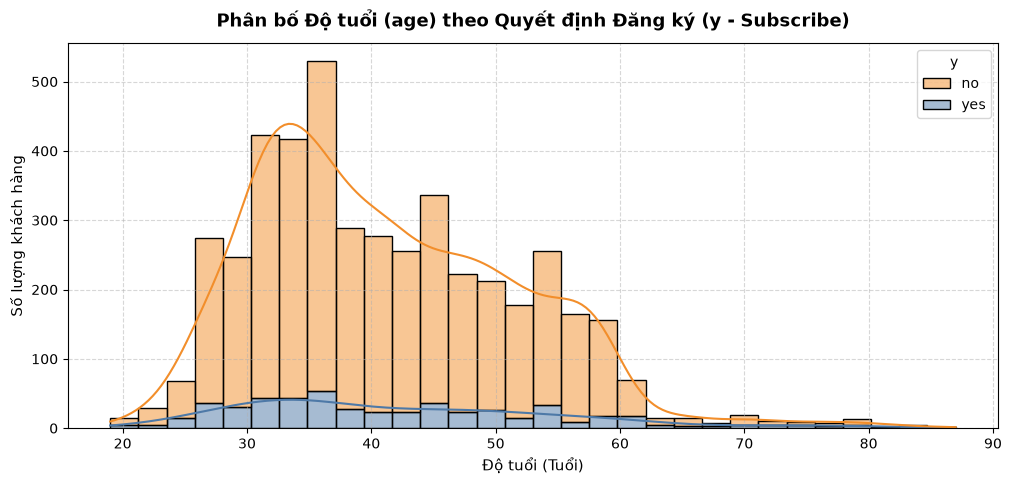

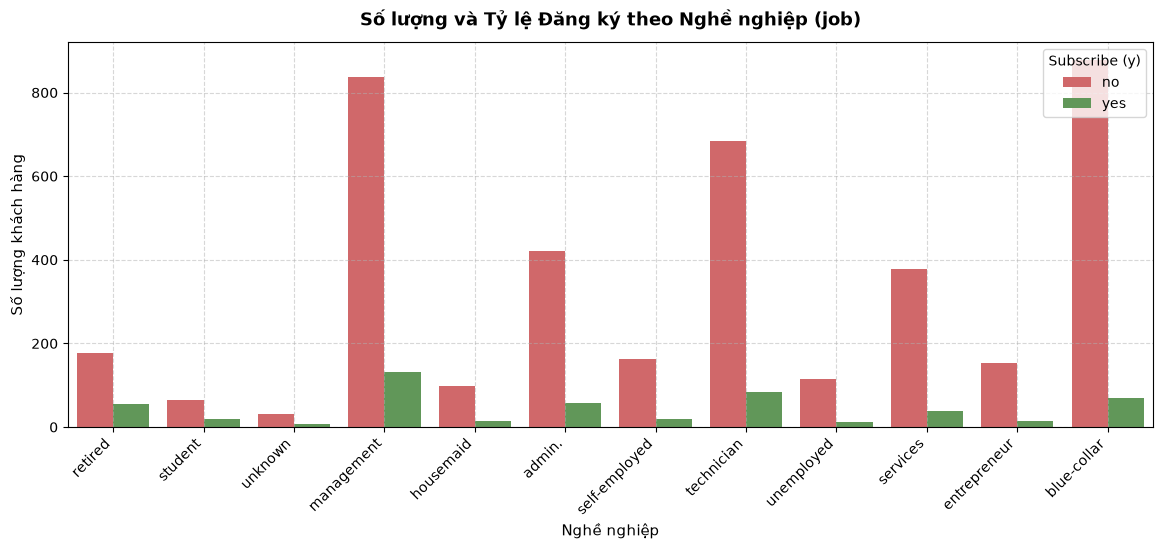

/tmp/ipykernel_217232/2070824332.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='marital', y=(df['y'] == 'yes').astype(float), palette='Blues_r', errorbar=None)


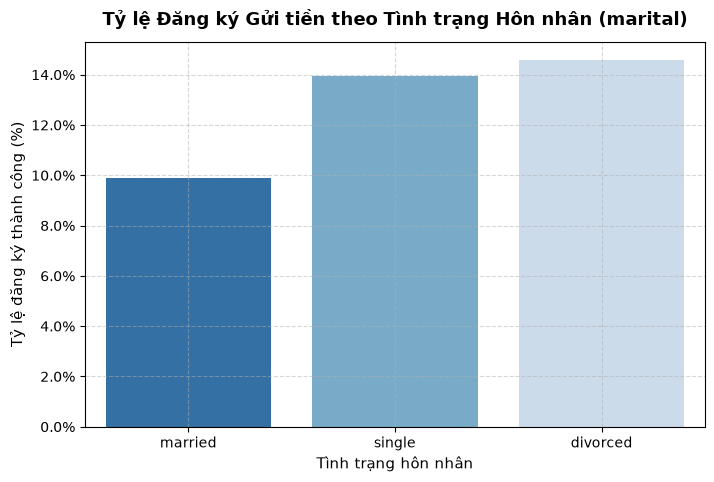

In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (Trang 28-29) - Câu 3: Khảo sát tương quan nhân khẩu học và quyết định y

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Thiết lập thư mục lưu ảnh
def get_img_dir(subpath=""):
    for base in [".", "..", "../.."]:
        img_root = os.path.join(base, "images")
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, "datasets")) or os.path.exists(os.path.join(base, "CLAUDE.md"))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join("images", subpath) if subpath else "images"
    os.makedirs(target, exist_ok=True)
    return target
img_dir = get_img_dir("Phan1/Bai2")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path)),
        os.path.join("..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", os.path.basename(rel_path)),
        os.path.join("..", "..", "datasets", "Bank", os.path.basename(rel_path)),
        os.path.join("datasets", "Bank", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

file_path = get_data_path("bank.csv")
df = pd.read_csv(file_path, sep=';')

# 1. Biểu đồ phân bố độ tuổi (age) theo quyết định đăng ký (y)
plt.figure(figsize=(12, 5))
sns.histplot(data=df, x='age', hue='y', multiple='stack', palette={'no': '#f28e2b', 'yes': '#4e79a7'}, bins=30, kde=True)
plt.title('Phân bố Độ tuổi (age) theo Quyết định Đăng ký (y - Subscribe)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Độ tuổi (Tuổi)', fontsize=11)
plt.ylabel('Số lượng khách hàng', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(os.path.join(img_dir, 'bank_age_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

# 2. Biểu đồ tỷ lệ đăng ký theo Nghề nghiệp (job)
plt.figure(figsize=(14, 5))
job_order = df.groupby('job')['y'].apply(lambda s: (s == 'yes').mean()).sort_values(ascending=False).index
sns.countplot(data=df, x='job', hue='y', order=job_order, palette={'no': '#e15759', 'yes': '#59a14f'})
plt.title('Số lượng và Tỷ lệ Đăng ký theo Nghề nghiệp (job)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Nghề nghiệp', fontsize=11)
plt.ylabel('Số lượng khách hàng', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Subscribe (y)', loc='upper right')
plt.savefig(os.path.join(img_dir, 'bank_job_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

# 3. Biểu đồ tỷ lệ đăng ký theo Tình trạng hôn nhân (marital)
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='marital', y=(df['y'] == 'yes').astype(float), palette='Blues_r', errorbar=None)
plt.title('Tỷ lệ Đăng ký Gửi tiền theo Tình trạng Hôn nhân (marital)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Tình trạng hôn nhân', fontsize=11)
plt.ylabel('Tỷ lệ đăng ký thành công (%)', fontsize=11)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.1f}%'))
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(os.path.join(img_dir, 'bank_marital_vs_y.png'), dpi=300, bbox_inches='tight')
plt.show()

### Nhận xét & Đánh giá (Câu 3):
1. **Độ tuổi (`age`)**:
   - Nhóm khách hàng từ 30 đến 50 tuổi chiếm số lượng tiếp cận lớn nhất, nhưng tỷ lệ đồng ý gửi tiền ở nhóm này ở mức trung bình (~10%).
   - Tỷ lệ đăng ký (`yes`) cao vượt trội ở hai thái cực: **người trẻ tuổi (< 25 tuổi)** và **người cao tuổi (> 60 tuổi)**. Đặc biệt nhóm trên 60 tuổi có tỷ lệ đăng ký lên tới > 25% vì nhu cầu bảo toàn vốn tích lũy hưởng lãi suất định kỳ.
2. **Nghề nghiệp (`job`)**:
   - Ba nhóm ngành có tỷ lệ đồng ý cao nhất là: **Học sinh/sinh viên (`student`)**, **Người nghỉ hưu (`retired`)** và **Thất nghiệp (`unemployed`)**.
   - Các nhóm ngành truyền thống như công nhân (`blue-collar`), nhân viên văn phòng (`services`, `admin.`) có số lượng tiếp cận đông nhưng tỷ lệ đồng ý gửi tiền thấp nhất (< 9%).
3. **Hôn nhân (`marital`)**:
   - Nhóm **Độc thân (`single`)** có tỷ lệ đăng ký cao nhất (~14%), cao hơn đáng kể so với nhóm **Đã kết hôn (`married`)** (~10%) và **Ly hôn (`divorced`)** (~12%).